In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [44]:
port.head()


,항구청명,사용년월,사용월,시설코드,시설서브코드,시설명,접안시간,처리실적
0,감천,2025,8,MKC,03,감천 중앙부두 3선석,401,66795
1,감천,2025,8,MK5,01,감천 5부두 1선석,902,15
2,감천,2025,8,MK4,01,감천 4부두 1선석(국제수산물부두),489,604
3,감천,2025,8,MK1,02,감천 1부두 2선석,1103,2350
4,감천,2025,8,MK2,03,감천 2부두 3선석,233,8064


In [70]:
berth = pd.read_excel("data/Berth_Schedule.xlsx", header=1)

C:\work\rere\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [71]:
berth.head()

,No,선석,항로,모선항차,선박명,선사항차,접안,선사,반입 시작일시,반입 마감일시,입항일시,출항일시,작업 시작일시,작업 완료일시,양하,선적,S/H,전배
0,1,1B,MS2W,HODM-2025-0003,HMM DIAMOND,004W-004W,S,HMM,2025-06-27 00:00,2025-06-30 03:00,2025-06-30 13:25,2025-07-01 15:00,2025-06-30 13:25,2025-07-01 14:02,2033,81,48,NaN
1,2,1B,PNSE,SCLK-2025-0008,KOTA LUKIS,2504E-2504E,P,SML,2025-06-28 00:00,2025-07-01 07:00,2025-07-01 16:55,2025-07-02 04:00,2025-07-01 17:48,2025-07-02 03:59,243,535,0,NaN
2,3,1B,CPXW,SMBS-2025-0007,SM BUSAN,2504W-2504W,S,SML,2025-06-29 00:00,2025-07-01 20:00,2025-07-02 06:10,2025-07-02 14:00,2025-07-02 08:00,2025-07-02 13:32,440,16,0,NaN
3,4,1B,BNX,SCSH-2025-0023,SCO SHANGHAI,25026E-25026E,S,BEN,2025-06-29 00:00,2025-07-02 06:00,2025-07-02 15:50,2025-07-03 04:30,2025-07-02 15:50,2025-07-03 04:30,218,240,0,NaN
4,5,1B,KF02,MGNA-2025-0001,MAGNA,4565W-4566E,S,KFC,2025-06-29 00:00,2025-07-02 06:00,2025-07-02 15:55,2025-07-03 00:00,2025-07-02 15:55,2025-07-02 23:06,198,87,0,NaN


In [65]:
berth.info()

<class 'pandas.DataFrame'>
RangeIndex: 1002 entries, 0 to 1001
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   No       1002 non-null   int64
 1   선석       1002 non-null   str  
 2   항로       1002 non-null   str  
 3   모선항차     1002 non-null   str  
 4   선박명      1002 non-null   str  
 5   선사항차     1002 non-null   str  
 6   접안       1002 non-null   str  
 7   선사       1002 non-null   str  
 8   반입 시작일시  1002 non-null   str  
 9   반입 마감일시  1002 non-null   str  
 10  입항일시     1002 non-null   str  
 11  출항일시     1002 non-null   str  
 12  작업 시작일시  1001 non-null   str  
 13  작업 완료일시  1002 non-null   str  
 14  양하       1002 non-null   int64
 15  선적       1002 non-null   int64
 16  S/H      1002 non-null   int64
 17  전배       1 non-null      str  
dtypes: int64(4), str(14)
memory usage: 141.0 KB


In [66]:
port1 = port.copy()
berth1 = berth.copy()

In [46]:
port1.columns = port.columns.astype(str).str.strip()

In [67]:
berth1.columns = berth1.columns.astype(str).str.strip()

In [50]:
port1.isna().sum().sort_values(ascending=False).head()

항구청명      0
사용년월      0
사용월       0
시설코드      0
시설서브코드    0
dtype: int64

In [68]:
berth1.isna().sum().sort_values(ascending=False).head()

전배         1001
작업 시작일시       1
선석            0
No            0
항로            0
dtype: int64

In [69]:
berth1.head()

,No,선석,항로,모선항차,선박명,선사항차,접안,선사,반입 시작일시,반입 마감일시,입항일시,출항일시,작업 시작일시,작업 완료일시,양하,선적,S/H,전배
0,1,1B,MD3,YWDM-2024-0002,YM WISDOM,020W-021W,S,YML,2024-12-28 00:00,2024-12-31 06:00,2024-12-31 15:54,2025-01-02 23:00,2024-12-31 17:30,2025-01-02 21:46,3122,1276,2166,NaN
1,2,1B,SIS2,ZGHZ-2025-0001,ZHONG GU HANG ZHOU,24005W-24005W,S,TSL,2024-12-31 00:00,2025-01-02 15:00,2025-01-03 00:55,2025-01-03 22:00,2025-01-03 14:10,2025-01-03 21:42,807,514,24,NaN
2,3,1B,JVH,OSWR-2025-0001,SWAN RIVER BRIDGE,105S-105S,S,ONE,2025-01-01 00:00,2025-01-03 14:00,2025-01-04 00:05,2025-01-04 11:00,2025-01-04 00:53,2025-01-04 10:59,252,444,6,NaN
3,4,1B,AIS,KKJA-2025-0001,KMTC JEBEL ALI,2409W-2409W,P,KMD,2025-01-01 00:00,2025-01-04 03:00,2025-01-04 13:50,2025-01-05 03:00,2025-01-04 14:50,2025-01-05 02:23,570,503,0,NaN
4,5,1B,PN3E,HOPD-2025-0001,HMM PERIDOT,004E-004E,S,HMM,2025-01-02 00:00,2025-01-04 19:00,2025-01-05 06:05,2025-01-07 05:01,2025-01-05 07:04,2025-01-07 03:40,1443,2737,12,NaN


In [52]:
berth1.duplicated().sum()

np.int64(0)

In [53]:
port1.duplicated().sum()

np.int64(0)

In [58]:
port1["접안시간"] = pd.to_numeric(
    port1["접안시간"], errors="coerce"
)

port1["처리실적"] = pd.to_numeric(
    port1["처리실적"], errors="coerce"
)

port1["시간당_처리량"] = (
    port1["처리실적"] / port1["접안시간"].where(port1["접안시간"] > 0)
)

print(port1.head())



  항구청명  사용년월  사용월 시설코드 시설서브코드                  시설명  접안시간   처리실적     시간당_처리량
0   감천  2025    8  MKC     03          감천 중앙부두 3선석   401  66795  166.571072
1   감천  2025    8  MK5     01           감천 5부두 1선석   902     15    0.016630
2   감천  2025    8  MK4     01  감천 4부두 1선석(국제수산물부두)   489    604    1.235174
3   감천  2025    8  MK1     02           감천 1부두 2선석  1103   2350    2.130553
4   감천  2025    8  MK2     03           감천 2부두 3선석   233   8064   34.609442


In [91]:

# 2. 날짜 컬럼 변환
date_cols = [
    "입항일시",
    "출항일시",
    "작업 시작일시",
    "작업 완료일시"
]

for col in date_cols:
    berth[col] = pd.to_datetime(berth[col], errors="coerce")

# 3. 숫자 컬럼 변환
for col in ["양하", "선적"]:
    berth[col] = pd.to_numeric(
        berth[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

# 4. 분석 기간 설정
start_date = "2025-08-01"
end_date = "2026-07-31 23:59:59"

berth = berth[
    (berth["입항일시"] >= start_date) &
    (berth["입항일시"] <= end_date)
].copy()

# 5. 시간 지표 계산 (단위: 시간)
berth["접안 체류시간"] = (
    berth["출항일시"] - berth["입항일시"]
).dt.total_seconds() / 3600

berth["실제 작업시간"] = (
    berth["작업 완료일시"] - berth["작업 시작일시"]
).dt.total_seconds() / 3600

berth["작업 전 시간"] = (
    berth["작업 시작일시"] - berth["입항일시"]
).dt.total_seconds() / 3600

berth["작업 후 시간"] = (
    berth["출항일시"] - berth["작업 완료일시"]
).dt.total_seconds() / 3600

berth["총 처리량"] = berth["양하"].fillna(0) + berth["선적"].fillna(0)

# 6. 이상치 및 잘못된 시간 기록 확인
invalid = berth[
    (berth["접안 체류시간"] < 0) |
    (berth["실제 작업시간"] < 0) |
    (berth["작업 전 시간"] < 0) |
    (berth["작업 후 시간"] < 0)
]

print("전체 기항 기록:", len(berth))
print("시간 오류 또는 확인 필요 기록:", len(invalid))

# 음수 시간 기록은 별도 검토 대상으로 분리
valid = berth[
    (berth["접안 체류시간"] >= 0) &
    (berth["실제 작업시간"] > 0) &
    (berth["작업 전 시간"] >= 0) &
    (berth["작업 후 시간"] >= 0)
].copy()

# 7. 기항별 작업 효율
valid["시간당 처리량"] = (
    valid["총 처리량"] / valid["실제 작업시간"]
)

valid["작업시간 비중(%)"] = (
    valid["실제 작업시간"] /
    valid["접안 체류시간"].replace(0, np.nan) * 100
)

# 8. 선석별 분석
berth_summary = valid.groupby("선석").agg(
    기항수=("선석", "size"),
    평균_체류시간=("접안 체류시간", "mean"),
    평균_작업시간=("실제 작업시간", "mean"),
    평균_작업전시간=("작업 전 시간", "mean"),
    평균_작업후시간=("작업 후 시간", "mean"),
    평균_처리량=("총 처리량", "mean"),
    평균_시간당처리량=("시간당 처리량", "mean")
).round(2)

print("\n[선석별 분석]")
print(berth_summary)

# 9. 월별 분석
valid["월"] = valid["입항일시"].dt.to_period("M").astype(str)

monthly = valid.groupby("월").agg(
    기항수=("선석", "size"),
    총_체류시간=("접안 체류시간", "sum"),
    평균_체류시간=("접안 체류시간", "mean"),
    평균_작업시간=("실제 작업시간", "mean"),
    평균_작업전시간=("작업 전 시간", "mean"),
    총_처리량=("총 처리량", "sum"),
    평균_시간당처리량=("시간당 처리량", "mean")
).round(2)

print("\n[월별 분석]")
print(monthly)

# 10. 결과 저장
valid.to_csv(
    "한진_기항별_분석.csv",
    index=False,
    encoding="utf-8-sig"
)

berth_summary.to_csv(
    "한진_선석별_분석.csv",
    encoding="utf-8-sig"
)

monthly.to_csv(
    "한진_월별_분석.csv",
    encoding="utf-8-sig"
)

print("\n분석 결과 CSV 저장 완료")

전체 기항 기록: 1080
시간 오류 또는 확인 필요 기록: 0

[선석별 분석]
    기항수  평균_체류시간  평균_작업시간  평균_작업전시간  평균_작업후시간   평균_처리량  평균_시간당처리량
선석                                                               
1B  327    21.47    19.56      0.72      1.19  1733.67      77.98
2B  426    14.52    12.58      0.71      1.23   835.81      60.63
3B  174    27.67    25.96      0.72      0.99  2695.34      86.87
4B  151    18.29    15.89      0.82      1.57  1193.68      79.32

[월별 분석]
         기항수   총_체류시간  평균_체류시간  평균_작업시간  평균_작업전시간   총_처리량  평균_시간당처리량
월                                                                   
2025-08   84  1505.55    17.92    15.95      0.76  108678      77.69
2025-09   94  1756.98    18.69    16.55      0.73  139428      76.36
2025-10   92  1609.92    17.50    15.35      0.96  114370      75.12
2025-11   87  1587.35    18.25    16.30      0.53  121520      70.20
2025-12   93  1724.17    18.54    16.21      0.58  116634      64.25
2026-01   81  1584.30    19.56    17.36      0.79  115386      68.

In [85]:
port = pd.read_csv("data/부산항 외항선 시설별 실적.csv", encoding='utf-8')

In [86]:
print(port.head())

  항구청명  사용년월  사용월 시설코드 시설서브코드                  시설명  접안시간   처리실적
0   감천  2025    8  MKC      3          감천 중앙부두 3선석   401  66795
1   감천  2025    8  MK5      1           감천 5부두 1선석   902     15
2   감천  2025    8  MK4      1  감천 4부두 1선석(국제수산물부두)   489    604
3   감천  2025    8  MK1      2           감천 1부두 2선석  1103   2350
4   감천  2025    8  MK2      3           감천 2부두 3선석   233   8064


In [94]:
# 원본 엑셀 파일 불러오기
df = pd.read_csv("data/부산항 외항선 시설별 실적.csv", encoding='utf-8')

# 신항 3부두의 1~4선석만 선택
filtered = df[
    (df["시설코드"].astype(str).str.strip() == "MS3") &
    (pd.to_numeric(df["시설서브코드"], errors="coerce").isin([1, 2, 3, 4]))
].copy()

# 필요한 기간만 선택: 2025년 8월 ~ 2026년 7월
year = pd.to_numeric(filtered["사용년월"], errors="coerce")
month = pd.to_numeric(filtered["사용월"], errors="coerce")

filtered = filtered[
    (
        ((year == 2025) & (month >= 8)) |
        ((year == 2026) & (month <= 7))
    )
].copy()

# 필터링 결과 확인
print("필터링된 행 수:", len(filtered))
print(filtered[["사용년월", "사용월", "시설명", "접안시간", "처리실적"]].head(10))

filtered.to_csv(
    "부산항_신항3부두_1-4선석_필터링.csv",
    index=False,
    encoding="utf-8-sig"
)



필터링된 행 수: 48
     사용년월  사용월         시설명  접안시간     처리실적
603  2025    8  신항 3부두 1선석   518  1375288
608  2025    8  신항 3부두 4선석   524   391641
609  2025    8  신항 3부두 3선석   420  1392563
617  2025    8  신항 3부두 2선석    65    64154
632  2025    9  신항 3부두 2선석   146   142099
645  2025    9  신항 3부두 1선석   475  1702700
648  2025    9  신항 3부두 3선석   525  1356558
650  2025    9  신항 3부두 4선석   621   338803
655  2025   10  신항 3부두 1선석   381  1634995
661  2025   10  신항 3부두 3선석   481  1228088


In [95]:
busan = pd.read_csv("부산항_신항3부두_1-4선석_필터링.csv", encoding='utf-8-sig')

In [96]:
busan.head()

,항구청명,사용년월,사용월,시설코드,시설서브코드,시설명,접안시간,처리실적
0,부산신항,2025,8,MS3,1,신항 3부두 1선석,518,1375288
1,부산신항,2025,8,MS3,4,신항 3부두 4선석,524,391641
2,부산신항,2025,8,MS3,3,신항 3부두 3선석,420,1392563
3,부산신항,2025,8,MS3,2,신항 3부두 2선석,65,64154
4,부산신항,2025,9,MS3,2,신항 3부두 2선석,146,142099


In [97]:
busan.columns = busan.columns.astype(str).str.strip()
berth.columns = berth.columns.astype(str).str.strip()


In [98]:
print(busan.shape)
print(berth.shape)

(48, 8)
(1080, 23)


In [101]:
# 날짜 열을 날짜 형식으로 변환
date_cols = [
    "입항일시",
    "출항일시",
    "작업 시작일시",
    "작업 완료일시"
]

for col in date_cols:
    berth[col] = pd.to_datetime(
        berth[col],
        errors="coerce"
    )

# 작업 시작일시에서 월 추출
berth["월"] = (
    berth["작업 시작일시"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# 2025년 8월 ~ 2026년 7월로 필터링
start = pd.Timestamp("2025-08-01")
end = pd.Timestamp("2026-08-01")

berth = berth[
    berth["월"].ge(start) &
    berth["월"].lt(end)
].copy()

# 확인
print("월 개수:", berth["월"].nunique())
print("\n월별 기록 수:")
print(berth.groupby("월").size())

월 개수: 12

월별 기록 수:
월
2025-08-01    84
2025-09-01    94
2025-10-01    92
2025-11-01    87
2025-12-01    93
2026-01-01    81
2026-02-01    83
2026-03-01    91
2026-04-01    95
2026-05-01    97
2026-06-01    90
2026-07-01    92
dtype: int64


In [102]:
# 부산항: 월별·선석별 데이터가 정확히 있는지 확인
print("부산항 월 개수:", busan["사용월"].nunique())
print("부산항 선석 개수:", busan["시설서브코드"].nunique())

print("\n월별 선석 기록 수")
print(
    busan.groupby("사용월")["시설서브코드"]
    .nunique()
)

print("\n월별·선석별 중복 확인")
print(
    busan.groupby(["사용월", "시설서브코드"])
    .size()
    .value_counts()
)

# 한진: 월별 선박 기록 수 확인
print("\n한진 월별 기록 수")
print(berth.groupby("월").size())

print("\n한진 선석별 기록 수")
print(berth["선석"].value_counts(dropna=False))

# 주요 날짜 열의 결측치 확인
date_cols = [
    "입항일시", "출항일시",
    "작업 시작일시", "작업 완료일시"
]

print("\n한진 주요 날짜 결측치")
print(berth[date_cols].isna().sum())

부산항 월 개수: 12
부산항 선석 개수: 4

월별 선석 기록 수
사용월
1     4
2     4
3     4
4     4
5     4
6     4
7     4
8     4
9     4
10    4
11    4
12    4
Name: 시설서브코드, dtype: int64

월별·선석별 중복 확인
1    48
Name: count, dtype: int64

한진 월별 기록 수
월
2025-08-01    84
2025-09-01    94
2025-10-01    92
2025-11-01    87
2025-12-01    93
2026-01-01    81
2026-02-01    83
2026-03-01    91
2026-04-01    95
2026-05-01    97
2026-06-01    90
2026-07-01    92
dtype: int64

한진 선석별 기록 수
선석
2B    426
1B    328
3B    174
4B    151
Name: count, dtype: int64

한진 주요 날짜 결측치
입항일시       0
출항일시       0
작업 시작일시    0
작업 완료일시    1
dtype: int64


In [103]:
# 1. 시간 데이터 변환
time_cols = [
    "입항일시",
    "출항일시",
    "작업 시작일시",
    "작업 완료일시"
]

for col in time_cols:
    berth[col] = pd.to_datetime(
        berth[col],
        errors="coerce"
    )

# 2. 월 생성
berth["월"] = berth["작업 시작일시"].dt.to_period("M")

# 3. 시간 지표 계산 (시간 단위)
berth["접안 체류시간"] = (
    berth["출항일시"] - berth["입항일시"]
).dt.total_seconds() / 3600

berth["작업 전 시간"] = (
    berth["작업 시작일시"] - berth["입항일시"]
).dt.total_seconds() / 3600

berth["실제 작업시간"] = (
    berth["작업 완료일시"] - berth["작업 시작일시"]
).dt.total_seconds() / 3600

berth["작업 후 시간"] = (
    berth["출항일시"] - berth["작업 완료일시"]
).dt.total_seconds() / 3600

# 4. 시간 지표의 비정상 값 확인
duration_cols = [
    "접안 체류시간",
    "작업 전 시간",
    "실제 작업시간",
    "작업 후 시간"
]

print("시간 지표 결측치")
print(berth[duration_cols].isna().sum())

print("\n음수 시간 기록")
print((berth[duration_cols] < 0).sum())

print("\n시간 지표 기술통계")
print(berth[duration_cols].describe().round(2))

시간 지표 결측치
접안 체류시간    0
작업 전 시간    0
실제 작업시간    1
작업 후 시간    1
dtype: int64

음수 시간 기록
접안 체류시간    0
작업 전 시간    0
실제 작업시간    0
작업 후 시간    0
dtype: int64

시간 지표 기술통계
       접안 체류시간  작업 전 시간  실제 작업시간  작업 후 시간
count  1079.00  1079.00  1078.00  1078.00
mean     19.28     0.73    17.32     1.23
std      11.86     1.31    11.77     2.12
min       2.00     0.00     0.58     0.00
25%      12.43     0.00    10.30     0.67
50%      16.50     0.50    14.78     1.02
75%      22.61     1.00    20.67     1.43
max      95.50    24.00    94.22    60.63


In [104]:
# 1. 선석별 시간 지표 비교
berth_summary = (
    berth.groupby("선석")
    .agg(
        기록수=("접안 체류시간", "count"),

        평균_체류시간=("접안 체류시간", "mean"),
        중앙값_체류시간=("접안 체류시간", "median"),
        상위10퍼센트_체류시간=(
            "접안 체류시간",
            lambda x: x.quantile(0.90)
        ),

        평균_작업전시간=("작업 전 시간", "mean"),
        중앙값_작업전시간=("작업 전 시간", "median"),

        평균_작업시간=("실제 작업시간", "mean"),
        중앙값_작업시간=("실제 작업시간", "median"),

        평균_작업후시간=("작업 후 시간", "mean"),
        중앙값_작업후시간=("작업 후 시간", "median")
    )
    .round(2)
    .sort_values("평균_체류시간", ascending=False)
)

print("===== 선석별 시간 지표 =====")
print(berth_summary)

# 2. 월별 시간 지표 비교
monthly_summary = (
    berth.groupby("월")
    .agg(
        기록수=("접안 체류시간", "count"),

        평균_체류시간=("접안 체류시간", "mean"),
        중앙값_체류시간=("접안 체류시간", "median"),

        평균_작업전시간=("작업 전 시간", "mean"),
        평균_작업시간=("실제 작업시간", "mean"),
        평균_작업후시간=("작업 후 시간", "mean")
    )
    .round(2)
)

print("\n===== 월별 시간 지표 =====")
print(monthly_summary)

# 3. 월별·선석별 비교
monthly_berth = (
    berth.groupby(["월", "선석"])
    .agg(
        기록수=("접안 체류시간", "count"),
        평균_체류시간=("접안 체류시간", "mean"),
        중앙값_체류시간=("접안 체류시간", "median"),
        평균_작업전시간=("작업 전 시간", "mean"),
        평균_작업시간=("실제 작업시간", "mean"),
        평균_작업후시간=("작업 후 시간", "mean")
    )
    .round(2)
    .reset_index()
)

print("\n===== 월별·선석별 시간 지표 =====")
print(monthly_berth.to_string(index=False))

# 4. 장시간 체류 기록 확인
long_stays = (
    berth.loc[
        berth["접안 체류시간"] >= 24,
        [
            "월",
            "선석",
            "입항일시",
            "작업 시작일시",
            "작업 완료일시",
            "출항일시",
            "접안 체류시간",
            "작업 전 시간",
            "실제 작업시간",
            "작업 후 시간"
        ]
    ]
    .sort_values("접안 체류시간", ascending=False)
)

print("\n===== 24시간 이상 체류 기록 =====")
print("기록 수:", len(long_stays))
print(long_stays.to_string(index=False))

# 5. 결과 저장
berth_summary.to_csv(
    "한진_선석별_시간분석.csv",
    encoding="utf-8-sig"
)

monthly_summary.to_csv(
    "한진_월별_시간분석.csv",
    encoding="utf-8-sig"
)

monthly_berth.to_csv(
    "한진_월별_선석별_시간분석.csv",
    index=False,
    encoding="utf-8-sig"
)

long_stays.to_csv(
    "한진_장시간체류_상세.csv",
    index=False,
    encoding="utf-8-sig"
)

===== 선석별 시간 지표 =====
    기록수  평균_체류시간  중앙값_체류시간  상위10퍼센트_체류시간  평균_작업전시간  중앙값_작업전시간  평균_작업시간  \
선석                                                                       
3B  174    27.67     22.92         50.83      0.72       0.46    25.96   
1B  328    21.47     18.00         38.59      0.73       0.50    19.56   
4B  151    18.29     17.33         26.50      0.82       0.50    15.89   
2B  426    14.52     14.33         22.83      0.71       0.50    12.58   

    중앙값_작업시간  평균_작업후시간  중앙값_작업후시간  
선석                                 
3B     21.38      0.99       0.90  
1B     16.22      1.19       1.08  
4B     15.50      1.57       1.03  
2B     12.38      1.23       1.03  

===== 월별 시간 지표 =====
         기록수  평균_체류시간  중앙값_체류시간  평균_작업전시간  평균_작업시간  평균_작업후시간
월                                                           
2025-08   84    17.92     16.29      0.76    15.95      1.21
2025-09   94    18.69     15.92      0.73    16.55      1.41
2025-10   92    17.50     15.08      0.96    15.35 

In [105]:
# 1. 24시간 이상 체류한 기록의 선석별 분포
long_stays = berth.loc[
    berth["접안 체류시간"] >= 24
].copy()

print("장시간 체류 기록의 선석별 건수")
print(long_stays["선석"].value_counts())

print("\n장시간 체류 기록의 월별 건수")
print(long_stays.groupby("월").size())

print("\n선석별 장시간 체류 비율")
print(
    (long_stays["선석"].value_counts()
     / berth["선석"].value_counts() * 100)
    .round(1)
)

# 2. 3B 선석의 월별 상세 분석
berth_3b = berth[berth["선석"] == "3B"].copy()

print("\n3B 월별 시간 지표")
print(
    berth_3b.groupby("월").agg(
        기록수=("접안 체류시간", "count"),
        평균_체류시간=("접안 체류시간", "mean"),
        중앙값_체류시간=("접안 체류시간", "median"),
        평균_작업시간=("실제 작업시간", "mean"),
        중앙값_작업시간=("실제 작업시간", "median"),
        평균_작업전=("작업 전 시간", "mean"),
        평균_작업후=("작업 후 시간", "mean")
    ).round(2)
)

# 3. 3B의 장시간 체류 사례
cols = [
    "월", "선석",
    "입항일시", "작업 시작일시",
    "작업 완료일시", "출항일시",
    "접안 체류시간", "실제 작업시간"
]

print("\n3B 장시간 체류 상위 15건")
print(
    berth_3b.nlargest(15, "접안 체류시간")[cols]
    .to_string(index=False)
)

# 4. 원본 데이터에 어떤 물량·선박 정보가 있는지 확인
print("\n전체 컬럼 목록")
print(berth.columns.tolist())

장시간 체류 기록의 선석별 건수
선석
1B    94
3B    83
2B    33
4B    21
Name: count, dtype: int64

장시간 체류 기록의 월별 건수
월
2025-08    14
2025-09    15
2025-10    20
2025-11    15
2025-12    21
2026-01    19
2026-02    20
2026-03    24
2026-04    17
2026-05    17
2026-06    23
2026-07    26
Freq: M, dtype: int64

선석별 장시간 체류 비율
선석
1B    28.7
2B     7.7
3B    47.7
4B    13.9
Name: count, dtype: float64

3B 월별 시간 지표
         기록수  평균_체류시간  중앙값_체류시간  평균_작업시간  중앙값_작업시간  평균_작업전  평균_작업후
월                                                                 
2025-08   15    28.90     26.83    27.47     26.62    0.44    0.99
2025-09   18    23.12     20.23    21.57     19.27    0.44    1.12
2025-10   15    23.16     21.92    21.68     21.08    0.63    0.85
2025-11   16    21.69     20.25    19.80     17.48    0.61    1.28
2025-12   21    23.41     22.08    22.09     20.92    0.53    0.78
2026-01   14    23.92     23.79    21.86     22.07    0.94    1.12
2026-02   13    21.60     20.50    19.95     18.55    0.92    0.73
2

In [106]:
# 전체 컬럼명과 데이터 유형
print("===== 컬럼 목록 =====")
print(berth.columns.tolist())

print("\n===== 데이터 유형 =====")
print(berth.dtypes)

print("\n===== 3B 선박 데이터 예시 =====")
print(
    berth.loc[
        berth["선석"] == "3B"
    ].head(5).to_string(index=False)
)

===== 컬럼 목록 =====
['No', '선석', '항로', '모선항차', '선박명', '선사항차', '접안', '선사', '반입 시작일시', '반입 마감일시', '입항일시', '출항일시', '작업 시작일시', '작업 완료일시', '양하', '선적', 'S/H', '전배', '접안 체류시간', '실제 작업시간', '작업 전 시간', '작업 후 시간', '총 처리량', '월']

===== 데이터 유형 =====
No                  int64
선석                    str
항로                    str
모선항차                  str
선박명                   str
선사항차                  str
접안                    str
선사                    str
반입 시작일시               str
반입 마감일시               str
입항일시       datetime64[us]
출항일시       datetime64[us]
작업 시작일시    datetime64[us]
작업 완료일시    datetime64[us]
양하                  int64
선적                  int64
S/H                 int64
전배                    str
접안 체류시간           float64
실제 작업시간           float64
작업 전 시간           float64
작업 후 시간           float64
총 처리량               int64
월               period[M]
dtype: object

===== 3B 선박 데이터 예시 =====
 No 선석   항로           모선항차          선박명        선사항차 접안  선사          반입 시작일시          반입 마감일시         

In [108]:
# 1. 선석별 처리량과 작업시간 비교
berth_workload = (
    berth.groupby("선석")
    .agg(
        기록수=("총 처리량", "count"),
        평균_처리량=("총 처리량", "mean"),
        중앙값_처리량=("총 처리량", "median"),
        평균_작업시간=("실제 작업시간", "mean"),
        중앙값_작업시간=("실제 작업시간", "median"),
        평균_체류시간=("접안 체류시간", "mean")
    )
    .round(2)
    .sort_values("평균_작업시간", ascending=False)
)

print("===== 선석별 처리량과 작업시간 =====")
print(berth_workload)

# 2. 처리량과 작업시간의 상관관계
print("\n===== 처리량-작업시간 상관관계 =====")

for berth1, df in berth.groupby("선석"):
    valid = df[["총 처리량", "실제 작업시간"]].dropna()

    print(f"\n[{berth1}]")
    print("표본 수:", len(valid))
    print(
        "피어슨 상관계수:",
        round(valid["총 처리량"].corr(
            valid["실제 작업시간"], method="pearson"
        ), 3)
    )
    print(
        "스피어만 상관계수:",
        round(valid["총 처리량"].corr(
            valid["실제 작업시간"], method="spearman"
        ), 3)
    )

# 3. 3B 월별 처리량과 작업시간 비교
berth_3b = berth[berth["선석"] == "3B"].copy()

monthly_3b = (
    berth_3b.groupby("월")
    .agg(
        기록수=("총 처리량", "count"),
        평균_처리량=("총 처리량", "mean"),
        중앙값_처리량=("총 처리량", "median"),
        총_처리량=("총 처리량", "sum"),
        평균_작업시간=("실제 작업시간", "mean"),
        중앙값_작업시간=("실제 작업시간", "median"),
        평균_체류시간=("접안 체류시간", "mean")
    )
    .round(2)
)

print("\n===== 3B 월별 처리량과 작업시간 =====")
print(monthly_3b)

# 4. 처리량 대비 시간당 처리량
berth["시간당_처리량"] = (
    berth["총 처리량"] / berth["실제 작업시간"]
)

print("\n===== 선석별 시간당 처리량 =====")
print(
    berth.groupby("선석")["시간당_처리량"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print("\n===== 3B 월별 시간당 처리량 =====")
print(
    berth_3b.assign(
        시간당_처리량=(
            berth_3b["총 처리량"] / berth_3b["실제 작업시간"]
        )
    )
    .groupby("월")["시간당_처리량"]
    .agg(["count", "mean", "median"])
    .round(2)
)

===== 선석별 처리량과 작업시간 =====
    기록수   평균_처리량  중앙값_처리량  평균_작업시간  중앙값_작업시간  평균_체류시간
선석                                                   
3B  174  2695.34   1662.0    25.96     21.38    27.67
1B  328  1732.67   1254.0    19.56     16.22    21.47
4B  151  1193.68   1037.0    15.89     15.50    18.29
2B  426   835.81    788.0    12.58     12.38    14.52

===== 처리량-작업시간 상관관계 =====

[1B]
표본 수: 327
피어슨 상관계수: 0.935
스피어만 상관계수: 0.892

[2B]
표본 수: 426
피어슨 상관계수: 0.88
스피어만 상관계수: 0.893

[3B]
표본 수: 174
피어슨 상관계수: 0.961
스피어만 상관계수: 0.959

[4B]
표본 수: 151
피어슨 상관계수: 0.835
스피어만 상관계수: 0.814

===== 3B 월별 처리량과 작업시간 =====
         기록수   평균_처리량  중앙값_처리량  총_처리량  평균_작업시간  중앙값_작업시간  평균_체류시간
월                                                                
2025-08   15  2889.60   2978.0  43344    27.47     26.62    28.90
2025-09   18  2332.89   1409.0  41992    21.57     19.27    23.12
2025-10   15  2312.40   1885.0  34686    21.68     21.08    23.16
2025-11   16  1877.50   1307.5  30040    19.80     17.48    21.69
202

In [109]:
# 3B 월별 집계 생산성
berth_3b = berth[berth["선석"] == "3B"].copy()

monthly_3b_productivity = (
    berth_3b.groupby("월")
    .agg(
        선박수=("총 처리량", "count"),
        총_처리량=("총 처리량", "sum"),
        총_작업시간=("실제 작업시간", "sum"),
        평균_처리량=("총 처리량", "mean"),
        평균_작업시간=("실제 작업시간", "mean"),
        중앙값_작업시간=("실제 작업시간", "median")
    )
)

# 총 처리량 / 총 작업시간
monthly_3b_productivity["집계_시간당_처리량"] = (
    monthly_3b_productivity["총_처리량"]
    / monthly_3b_productivity["총_작업시간"]
)

print(monthly_3b_productivity.round(2))

# 2025년 8월~2026년 5월과 6~7월 비교
baseline = monthly_3b_productivity.loc[
    "2025-08":"2026-05"
]

recent = monthly_3b_productivity.loc[
    "2026-06":"2026-07"
]

cols = [
    "총_처리량",
    "총_작업시간",
    "평균_처리량",
    "평균_작업시간",
    "집계_시간당_처리량"
]

print("\n===== 이전 기간 vs 최근 2개월 =====")
print("이전 10개월 평균")
print(baseline[cols].mean().round(2))

print("\n최근 2개월 평균")
print(recent[cols].mean().round(2))

         선박수  총_처리량  총_작업시간   평균_처리량  평균_작업시간  중앙값_작업시간  집계_시간당_처리량
월                                                                  
2025-08   15  43344  411.98  2889.60    27.47     26.62      105.21
2025-09   18  41992  388.18  2332.89    21.57     19.27      108.18
2025-10   15  34686  325.22  2312.40    21.68     21.08      106.66
2025-11   16  30040  316.87  1877.50    19.80     17.48       94.80
2025-12   21  37302  463.95  1776.29    22.09     20.92       80.40
2026-01   14  28170  306.02  2012.14    21.86     22.07       92.05
2026-02   13  20447  259.37  1572.85    19.95     18.55       78.83
2026-03   12  31739  306.13  2644.92    25.51     20.58      103.68
2026-04   11  37189  321.48  3380.82    29.23     22.53      115.68
2026-05   15  48761  406.90  3250.73    27.13     12.43      119.84
2026-06   12  55948  487.30  4662.33    40.61     35.85      114.81
2026-07   12  59371  523.27  4947.58    43.61     42.43      113.46

===== 이전 기간 vs 최근 2개월 =====
이전 10개월 평균
총_처리량   

In [110]:
berth_3b_valid = berth_3b.dropna(
    subset=["총 처리량", "실제 작업시간"]
).copy()

# 작업시간이 0 이하인 행 제외
berth_3b_valid = berth_3b_valid[
    berth_3b_valid["실제 작업시간"] > 0
].copy()

berth_3b_valid["시간당_처리량"] = (
    berth_3b_valid["총 처리량"]
    / berth_3b_valid["실제 작업시간"]
)

monthly_efficiency = (
    berth_3b_valid.groupby("월")
    .agg(
        선박수=("총 처리량", "count"),
        평균_처리량=("총 처리량", "mean"),
        중앙값_처리량=("총 처리량", "median"),
        평균_작업시간=("실제 작업시간", "mean"),
        중앙값_작업시간=("실제 작업시간", "median"),
        시간당_처리량_중앙값=("시간당_처리량", "median"),
        시간당_처리량_평균=("시간당_처리량", "mean")
    )
)

print(monthly_efficiency.round(2))

         선박수   평균_처리량  중앙값_처리량  평균_작업시간  중앙값_작업시간  시간당_처리량_중앙값  시간당_처리량_평균
월                                                                         
2025-08   15  2889.60   2978.0    27.47     26.62       100.84      100.79
2025-09   18  2332.89   1409.0    21.57     19.27        84.27       92.95
2025-10   15  2312.40   1885.0    21.68     21.08        82.59       92.54
2025-11   16  1877.50   1307.5    19.80     17.48        80.53       81.04
2025-12   21  1776.29   1539.0    22.09     20.92        69.95       75.25
2026-01   14  2012.14   1838.0    21.86     22.07        81.86       74.89
2026-02   13  1572.85   1180.0    19.95     18.55        67.42       71.58
2026-03   12  2644.92   1822.5    25.51     20.58        89.70       91.06
2026-04   11  3380.82   2905.0    29.23     22.53       116.23       95.10
2026-05   15  3250.73    700.0    27.13     12.43        66.93       82.96
2026-06   12  4662.33   3202.5    40.61     35.85        99.56       97.36
2026-07   12  4947.58   4

In [112]:

df = berth_3b.dropna(
    subset=["총 처리량", "실제 작업시간"]
).copy()

df = df[
    (df["총 처리량"] > 0) &
    (df["실제 작업시간"] > 0)
].copy()

# 처리량과 작업시간의 관계를 로그 변환해 분석
df["로그_처리량"] = np.log1p(df["총 처리량"])
df["로그_작업시간"] = np.log1p(df["실제 작업시간"])

# 처리량으로 예상되는 작업시간 추정
from sklearn.linear_model import LinearRegression

model = LinearRegression()
X = df[["로그_처리량"]]
y = df["로그_작업시간"]

model.fit(X, y)

df["예상_로그_작업시간"] = model.predict(X)
df["작업시간_잔차"] = (
    df["로그_작업시간"] - df["예상_로그_작업시간"]
)

# 잔차가 클수록 같은 처리량 기준으로 작업시간이 긴 사례
df["작업시간_잔차_표준화"] = (
    df["작업시간_잔차"] - df["작업시간_잔차"].mean()
) / df["작업시간_잔차"].std()

df["월"] = df["작업 시작일시"].dt.to_period("M")

monthly_residual = (
    df.groupby("월")
    .agg(
        선박수=("작업시간_잔차_표준화", "count"),
        평균_잔차=("작업시간_잔차_표준화", "mean"),
        중앙값_잔차=("작업시간_잔차_표준화", "median"),
        장시간_작업_비율=(
            "작업시간_잔차_표준화",
            lambda s: (s > 1).mean() * 100
        )
    )
)

print(monthly_residual.round(2))

         선박수  평균_잔차  중앙값_잔차  장시간_작업_비율
월                                     
2025-08   15  -0.10   -0.07      13.33
2025-09   18  -0.51   -0.73       5.56
2025-10   15  -0.44   -0.58       0.00
2025-11   16  -0.25   -0.35       0.00
2025-12   21   0.25    0.40      23.81
2026-01   14   0.39   -0.02      21.43
2026-02   13   0.22   -0.08      30.77
2026-03   12  -0.35   -0.56       8.33
2026-04   11  -0.09    0.14       0.00
2026-05   15   0.01   -0.01      20.00
2026-06   12   0.55    0.11      25.00
2026-07   12   0.52    0.54      25.00


In [114]:
# 2026년 6~7월 중 처리량 대비 작업시간이 긴 선박 확인
recent_long_work = df[
    (df["월"] >= pd.Period("2026-06", freq="M")) &
    (df["월"] <= pd.Period("2026-07", freq="M"))
].sort_values(
    "작업시간_잔차_표준화",
    ascending=False
)

cols = [
    "월", "선석", "항로", "선박명",
    "총 처리량", "실제 작업시간",
    "접안 체류시간", "작업시간_잔차_표준화"
]

print(recent_long_work[cols].head(10).round(2))

            월  선석    항로               선박명  총 처리량  실제 작업시간  접안 체류시간  \
1057  2026-07  3B   FE4         ONE TRUTH   9691    94.22    95.50   
1050  2026-06  3B   FE4      ZENITH LUMOS   8786    86.98    87.92   
1066  2026-07  3B   FE4     ONE INTEGRITY   9880    91.40    93.17   
1052  2026-06  3B   JVH       SMOOTH WIND    801    18.65    20.53   
1049  2026-06  3B  FP2W       YM TUTORIAL   3338    41.80    43.08   
1061  2026-07  3B   FE4       ONE TRIBUTE   8322    67.10    69.65   
1053  2026-06  3B   FE4  ONE INTELLIGENCE  11692    77.33    80.58   
1065  2026-07  3B   FE4       ONE TRIUMPH   8918    65.92    67.50   
1054  2026-06  3B  FP2W     ONE FANTASTIC   3964    40.87    41.00   
1063  2026-07  3B  EC2E       ONE COLUMBA   4406    42.25    44.00   

      작업시간_잔차_표준화  
1057         2.38  
1050         2.26  
1066         2.16  
1052         1.61  
1049         1.38  
1061         1.06  
1053         0.76  
1065         0.75  
1054         0.74  
1063         0.58  


C:\Users\user\AppData\Local\Temp\ipykernel_5184\1094079546.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(recent_long_work[cols].head(10).round(2))


In [116]:
df_3b = berth[
    berth["선석"] == "3B"
].dropna(
    subset=["총 처리량", "실제 작업시간", "항로", "선박명"]
).copy()

df_3b = df_3b[
    (df_3b["총 처리량"] > 0) &
    (df_3b["실제 작업시간"] > 0)
].copy()

df_3b["시간당_처리량"] = (
    df_3b["총 처리량"] / df_3b["실제 작업시간"]
)

df_3b["24시간_이상"] = (
    df_3b["실제 작업시간"] >= 24
)

route_summary = (
    df_3b.groupby("항로")
    .agg(
        선박수=("선박명", "count"),
        평균_처리량=("총 처리량", "mean"),
        중앙값_처리량=("총 처리량", "median"),
        평균_작업시간=("실제 작업시간", "mean"),
        중앙값_작업시간=("실제 작업시간", "median"),
        평균_시간당_처리량=("시간당_처리량", "mean"),
        중앙값_시간당_처리량=("시간당_처리량", "median"),
        시간초과_비율=("24시간_이상", "mean"),
    )
)

route_summary["24시간_이상_비율(%)"] = (
    route_summary["시간초과_비율"] * 100
)

route_summary = route_summary.drop(
    columns=["시간초과_비율"]
)

print(
    route_summary
    .sort_values("평균_작업시간", ascending=False)
    .round(2)
)

       선박수   평균_처리량  중앙값_처리량  평균_작업시간  중앙값_작업시간  평균_시간당_처리량  중앙값_시간당_처리량  \
항로                                                                         
FE4     16  8992.12   9393.0    68.16     66.95      133.43       135.56   
EC2E     1  4406.00   4406.0    42.25     42.25      104.28       104.28   
FE3     11  5032.45   4680.0    37.56     33.73      135.11       136.93   
MD2     15  4083.47   4271.0    35.53     37.45      114.93       114.35   
MS2W     5  3907.00   4205.0    34.55     37.90      109.15       120.21   
FP2W     8  3299.00   3181.5    34.10     34.27       94.05        92.93   
PNIT     7  3133.86   3029.0    30.59     26.62       99.86       101.82   
HPNT     1  2430.00   2430.0    29.17     29.17       83.31        83.31   
PNC      1  3376.00   3376.0    25.90     25.90      130.35       130.35   
GS2W    15  2169.07   1734.0    24.37     23.37       87.79        88.52   
EC4E     9  2033.56   1833.0    22.89     22.23       87.58        86.68   
EC2W     4  

In [117]:
# 3B 선석의 FE4 항로만 추출
fe4 = df_3b[df_3b["항로"] == "FE4"].copy()

# 월별 작업 특성 비교
fe4_monthly = (
    fe4.groupby("월")
    .agg(
        선박수=("선박명", "count"),
        평균_처리량=("총 처리량", "mean"),
        중앙값_처리량=("총 처리량", "median"),
        평균_작업시간=("실제 작업시간", "mean"),
        중앙값_작업시간=("실제 작업시간", "median"),
        평균_시간당_처리량=("시간당_처리량", "mean"),
        중앙값_시간당_처리량=("시간당_처리량", "median")
    )
)

print(fe4_monthly.round(2))

         선박수    평균_처리량  중앙값_처리량  평균_작업시간  중앙값_작업시간  평균_시간당_처리량  중앙값_시간당_처리량
월                                                                          
2025-12    1   4252.00   4252.0    33.93     33.93      125.30       125.30
2026-04    3   7426.67   6693.0    57.21     53.98      129.44       134.85
2026-05    3  10988.00  10800.0    73.56     70.55      150.37       153.08
2026-06    4   9504.25   9290.0    69.88     69.53      138.94       148.05
2026-07    5   9272.20   9550.0    76.98     67.10      122.88       124.02


In [118]:
fe4_detail = fe4.sort_values(
    ["월", "실제 작업시간"],
    ascending=[True, False]
)

cols = [
    "월",
    "선박명",
    "총 처리량",
    "실제 작업시간",
    "접안 체류시간",
    "작업 전 시간",
    "작업 후 시간",
    "시간당_처리량"
]

print(fe4_detail[cols].round(2).to_string(index=False))

      월              선박명  총 처리량  실제 작업시간  접안 체류시간  작업 전 시간  작업 후 시간  시간당_처리량
2025-12     ONE INFINITY   4252    33.93    34.68     0.02     0.73   125.30
2026-04     ONE INFINITY   9236    68.00    70.25     2.25     0.00   135.82
2026-04    ONE INTEGRITY   6351    53.98    54.70     0.67     0.05   117.65
2026-04        ONE TRUST   6693    49.63    51.50     1.50     0.37   134.85
2026-05    ONE INGENUITY  11373    83.33    86.50     2.00     1.17   136.48
2026-05   ONE INNOVATION  10800    70.55    72.33     0.33     1.45   153.08
2026-05    ONE TRADITION  10791    66.80    70.17     1.83     1.53   161.54
2026-06     ZENITH LUMOS   8786    86.98    87.92     0.00     0.93   101.01
2026-06 ONE INTELLIGENCE  11692    77.33    80.58     0.58     2.67   151.19
2026-06     ONE TREASURE   9794    61.73    63.25     0.25     1.27   158.65
2026-06       ZEUS LUMOS   7745    53.45    55.08     0.08     1.55   144.90
2026-07        ONE TRUTH   9691    94.22    95.50     1.00     0.28   102.86

C:\Users\user\AppData\Local\Temp\ipykernel_5184\1806056549.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(fe4_detail[cols].round(2).to_string(index=False))


In [119]:
fe4_monthly_detail = (
    fe4.groupby("월")
    .agg(
        선박수=("선박명", "count"),
        중앙값_처리량=("총 처리량", "median"),
        중앙값_작업시간=("실제 작업시간", "median"),
        중앙값_시간당_처리량=("시간당_처리량", "median"),
        최저_시간당_처리량=("시간당_처리량", "min"),
        최고_시간당_처리량=("시간당_처리량", "max")
    )
)

print(fe4_monthly_detail.round(2))

         선박수  중앙값_처리량  중앙값_작업시간  중앙값_시간당_처리량  최저_시간당_처리량  최고_시간당_처리량
월                                                                   
2025-12    1   4252.0     33.93       125.30      125.30      125.30
2026-04    3   6693.0     53.98       134.85      117.65      135.82
2026-05    3  10800.0     70.55       153.08      136.48      161.54
2026-06    4   9290.0     69.53       148.05      101.01      158.65
2026-07    5   9550.0     67.10       124.02      102.86      144.15


In [120]:
# FE4 항로의 작업시간 분포 확인
fe4 = df_3b[df_3b['항로'] == 'FE4'].copy()

# 작업시간이 긴 순서대로 확인
fe4_detail = fe4[
    ['월', '선박명', '총 처리량',
     '실제 작업시간', '접안 체류시간',
     '작업 전 시간', '작업 후 시간', '시간당_처리량']
].sort_values('실제 작업시간', ascending=False)

display(fe4_detail)

,월,선박명,총 처리량,실제 작업시간,접안 체류시간,작업 전 시간,작업 후 시간,시간당_처리량
1057,2026-07,ONE TRUTH,9691,94.216667,95.500000,1.000000,0.283333,102.858659
1066,2026-07,ONE INTEGRITY,9880,91.400000,93.166667,1.000000,0.766667,108.096280
1050,2026-06,ZENITH LUMOS,8786,86.983333,87.916667,0.000000,0.933333,101.007856
1042,2026-05,ONE INGENUITY,11373,83.333333,86.500000,2.000000,1.166667,136.476000
1053,2026-06,ONE INTELLIGENCE,11692,77.333333,80.583333,0.583333,2.666667,151.189655
1032,2026-05,ONE INNOVATION,10800,70.550000,72.333333,0.333333,1.450000,153.082920
1027,2026-04,ONE INFINITY,9236,68.000000,70.250000,2.250000,0.000000,135.823529
1061,2026-07,ONE TRIBUTE,8322,67.100000,69.650000,0.650000,1.900000,124.023845
1041,2026-05,ONE TRADITION,10791,66.800000,70.166667,1.833333,1.533333,161.541916
1055,2026-07,ONE INSPIRATION,9550,66.250000,71.616667,1.616667,3.750000,144.150943


In [121]:
# 부산항 데이터의 컬럼 확인
print(busan.columns.tolist())

# 월별·시설별 접안시간 및 처리실적 확인
display(
    busan.sort_values(['사용년월', '시설명'])
)

['항구청명', '사용년월', '사용월', '시설코드', '시설서브코드', '시설명', '접안시간', '처리실적']


,항구청명,사용년월,사용월,시설코드,시설서브코드,시설명,접안시간,처리실적
0,부산신항,2025,8,MS3,1,신항 3부두 1선석,518,1375288
5,부산신항,2025,9,MS3,1,신항 3부두 1선석,475,1702700
8,부산신항,2025,10,MS3,1,신항 3부두 1선석,381,1634995
12,부산신항,2025,11,MS3,1,신항 3부두 1선석,315,1640378
16,부산신항,2025,12,MS3,1,신항 3부두 1선석,481,1668256
3,부산신항,2025,8,MS3,2,신항 3부두 2선석,65,64154
4,부산신항,2025,9,MS3,2,신항 3부두 2선석,146,142099
11,부산신항,2025,10,MS3,2,신항 3부두 2선석,209,52550
15,부산신항,2025,11,MS3,2,신항 3부두 2선석,256,87777
18,부산신항,2025,12,MS3,2,신항 3부두 2선석,231,92575


,사용년월,시설명,접안시간,처리실적
0,2025-08-01,신항 3부두 1선석,518,1375288
5,2025-09-01,신항 3부두 1선석,475,1702700
8,2025-10-01,신항 3부두 1선석,381,1634995
12,2025-11-01,신항 3부두 1선석,315,1640378
16,2025-12-01,신항 3부두 1선석,481,1668256
21,2026-01-01,신항 3부두 1선석,479,1622242
25,2026-02-01,신항 3부두 1선석,404,1786975
30,2026-03-01,신항 3부두 1선석,438,1785332
34,2026-04-01,신항 3부두 1선석,549,1526019
38,2026-05-01,신항 3부두 1선석,593,1715990


C:\Users\user\AppData\Local\Temp\ipykernel_5184\1064129478.py:44: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,사용년월,접안시간,처리실적,접안시간_변화율(%),처리실적_변화율(%)
0,2025-08-01,518,1375288,NaN,NaN
5,2025-09-01,475,1702700,-8.30,23.81
8,2025-10-01,381,1634995,-19.79,-3.98
12,2025-11-01,315,1640378,-17.32,0.33
16,2025-12-01,481,1668256,52.70,1.70
21,2026-01-01,479,1622242,-0.42,-2.76
25,2026-02-01,404,1786975,-15.66,10.15
30,2026-03-01,438,1785332,8.42,-0.09
34,2026-04-01,549,1526019,25.34,-14.52
38,2026-05-01,593,1715990,8.01,12.45


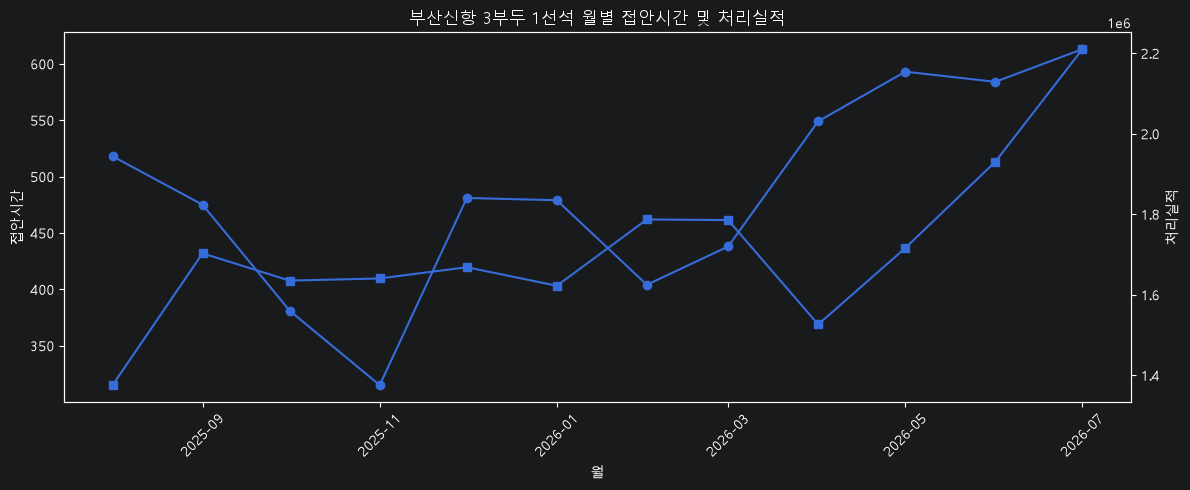

In [122]:
import pandas as pd
import matplotlib.pyplot as plt

# 연도와 월을 날짜로 변환
busan['사용년월'] = pd.to_datetime(
    busan['사용년월'].astype(str)
    + '-'
    + busan['사용월'].astype(str).str.zfill(2),
    format='%Y-%m'
)

# 숫자형으로 변환
for col in ['접안시간', '처리실적']:
    busan[col] = pd.to_numeric(
        busan[col], errors='coerce'
    )

# 분석 대상 선석 선택
target = busan[
    (busan['시설코드'] == 'MS3')
    & (busan['시설서브코드'] == 1)
].sort_values('사용년월').copy()

# 월별 표 확인
display(
    target[
        ['사용년월', '시설명', '접안시간', '처리실적']
    ]
)

# 월별 변화율 계산
target['접안시간_변화율(%)'] = (
    target['접안시간'].pct_change() * 100
)

target['처리실적_변화율(%)'] = (
    target['처리실적'].pct_change() * 100
)

display(
    target[
        ['사용년월', '접안시간', '처리실적',
         '접안시간_변화율(%)', '처리실적_변화율(%)']
    ].round(2)
)

# 추이 시각화
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(
    target['사용년월'],
    target['접안시간'],
    marker='o',
    label='접안시간'
)
ax1.set_xlabel('월')
ax1.set_ylabel('접안시간')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
ax2.plot(
    target['사용년월'],
    target['처리실적'],
    marker='s',
    label='처리실적'
)
ax2.set_ylabel('처리실적')

plt.title('부산신항 3부두 1선석 월별 접안시간 및 처리실적')
fig.tight_layout()
plt.show()

In [123]:
# 원본 데이터 복사
berth_analysis = busan.copy()

# 월 정보가 날짜형이면 그대로 사용
berth_analysis['사용년월'] = pd.to_datetime(
    berth_analysis['사용년월']
)

# 숫자형 확인
for col in ['접안시간', '처리실적']:
    berth_analysis[col] = pd.to_numeric(
        berth_analysis[col], errors='coerce'
    )

# 접안시간 대비 처리실적 계산
berth_analysis['시간당_처리실적'] = (
    berth_analysis['처리실적']
    / berth_analysis['접안시간'].replace(0, pd.NA)
)

# 선석별 월별 지표
berth_monthly = berth_analysis.sort_values(
    ['시설명', '사용년월']
).copy()

berth_monthly['접안시간_변화율(%)'] = (
    berth_monthly.groupby('시설명')['접안시간']
    .pct_change() * 100
)

berth_monthly['처리실적_변화율(%)'] = (
    berth_monthly.groupby('시설명')['처리실적']
    .pct_change() * 100
)

berth_monthly['시간당_처리실적_변화율(%)'] = (
    berth_monthly.groupby('시설명')['시간당_처리실적']
    .pct_change() * 100
)

display(
    berth_monthly[
        ['사용년월', '시설명', '접안시간', '처리실적',
         '시간당_처리실적',
         '접안시간_변화율(%)',
         '처리실적_변화율(%)',
         '시간당_처리실적_변화율(%)']
    ].round(2)
)

C:\Users\user\AppData\Local\Temp\ipykernel_5184\2480811101.py:48: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,사용년월,시설명,접안시간,처리실적,시간당_처리실적,접안시간_변화율(%),처리실적_변화율(%),시간당_처리실적_변화율(%)
0,2025-08-01,신항 3부두 1선석,518,1375288,2655.00,NaN,NaN,NaN
5,2025-09-01,신항 3부두 1선석,475,1702700,3584.63,-8.30,23.81,35.01
8,2025-10-01,신항 3부두 1선석,381,1634995,4291.33,-19.79,-3.98,19.71
12,2025-11-01,신항 3부두 1선석,315,1640378,5207.55,-17.32,0.33,21.35
16,2025-12-01,신항 3부두 1선석,481,1668256,3468.31,52.70,1.70,-33.40
21,2026-01-01,신항 3부두 1선석,479,1622242,3386.73,-0.42,-2.76,-2.35
25,2026-02-01,신항 3부두 1선석,404,1786975,4423.21,-15.66,10.15,30.60
30,2026-03-01,신항 3부두 1선석,438,1785332,4076.10,8.42,-0.09,-7.85
34,2026-04-01,신항 3부두 1선석,549,1526019,2779.63,25.34,-14.52,-31.81
38,2026-05-01,신항 3부두 1선석,593,1715990,2893.74,8.01,12.45,4.11


In [124]:
# 1. 3선석의 최근 데이터 확인
berth3 = berth_analysis[
    berth_analysis['시설명'] == '신항 3부두 3선석'
].sort_values('사용년월')

display(
    berth3[
        ['사용년월', '시설코드', '시설서브코드',
         '접안시간', '처리실적', '시간당_처리실적']
    ].tail(6)
)

# 2. 선석별 전체 기간과 최근 4개월 비교
summary = (
    berth_analysis
    .assign(기간=lambda x: x['사용년월'].apply(
        lambda d: '최근 4개월' if d >= pd.Timestamp('2026-04-01')
        else '이전 8개월'
    ))
    .groupby(['시설명', '기간'])
    .agg(
        월수=('사용년월', 'nunique'),
        평균_접안시간=('접안시간', 'mean'),
        평균_처리실적=('처리실적', 'mean'),
        평균_시간당_처리실적=('시간당_처리실적', 'mean')
    )
    .round(2)
)

display(summary)

,사용년월,시설코드,시설서브코드,접안시간,처리실적,시간당_처리실적
24,2026-02-01,MS3,3,454,1469569,3236.936123
28,2026-03-01,MS3,3,531,1890357,3559.994350
35,2026-04-01,MS3,3,541,1566437,2895.447320
37,2026-05-01,MS3,3,589,2151747,3653.220713
40,2026-06-01,MS3,3,552,2360557,4276.371377
47,2026-07-01,MS3,3,665,5685081,8548.993985


월수  평균_접안시간     평균_처리실적  평균_시간당_처리실적
시설명        기간                                          
신항 3부두 1선석 이전 8개월   8   436.38  1652020.75      3886.61
           최근 4개월   4   584.75  1845612.75      3146.03
신항 3부두 2선석 이전 8개월   8   177.75    87537.00       565.01
           최근 4개월   4   115.00    54506.25       510.47
신항 3부두 3선석 이전 8개월   8   470.88  1405220.25      2987.05
           최근 4개월   4   586.75  2940955.50      4843.51
신항 3부두 4선석 이전 8개월   8   580.12   407887.12       703.56
           최근 4개월   4   615.50   553608.00       905.45

In [125]:
# 선석별 최근 4개월 데이터
recent = berth_analysis[
    berth_analysis['사용년월']
    >= pd.Timestamp('2026-04-01')
].copy()

# 3선석의 7월 제외 전후 비교
berth3_recent = recent[
    recent['시설명'] == '신항 3부두 3선석'
]

display(
    berth3_recent[
        ['사용년월', '시설명', '접안시간',
         '처리실적', '시간당_처리실적']
    ].sort_values('사용년월')
)

# 7월을 포함한 최근 4개월과 제외한 3개월 비교
comparison = pd.DataFrame({
    '7월 포함': berth3_recent[
        ['접안시간', '처리실적', '시간당_처리실적']
    ].mean(),
    '7월 제외': berth3_recent[
        berth3_recent['사용년월']
        < pd.Timestamp('2026-07-01')
    ][['접안시간', '처리실적', '시간당_처리실적']].mean()
})

display(comparison.round(2))

,사용년월,시설명,접안시간,처리실적,시간당_처리실적
35,2026-04-01,신항 3부두 3선석,541,1566437,2895.447320
37,2026-05-01,신항 3부두 3선석,589,2151747,3653.220713
40,2026-06-01,신항 3부두 3선석,552,2360557,4276.371377
47,2026-07-01,신항 3부두 3선석,665,5685081,8548.993985


,7월 포함,7월 제외
접안시간,586.75,560.67
처리실적,2940955.50,2026247.00
시간당_처리실적,4843.51,3608.35


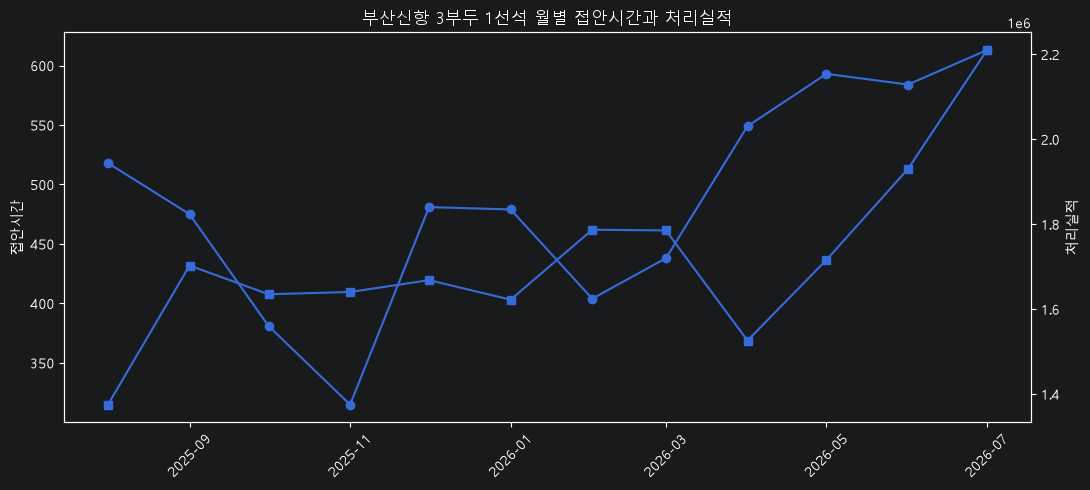

In [126]:
import matplotlib.pyplot as plt

target = berth_analysis[
    berth_analysis['시설명'] == '신항 3부두 1선석'
].sort_values('사용년월')

fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(
    target['사용년월'],
    target['접안시간'],
    marker='o',
    label='접안시간'
)
ax1.set_ylabel('접안시간')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
ax2.plot(
    target['사용년월'],
    target['처리실적'],
    marker='s',
    label='처리실적'
)
ax2.set_ylabel('처리실적')

plt.title('부산신항 3부두 1선석 월별 접안시간과 처리실적')
fig.tight_layout()
plt.show()

In [127]:
target = berth_analysis[
    berth_analysis['시설명'] == '신항 3부두 1선석'
].sort_values('사용년월')

print(
    target[
        ['사용년월', '접안시간', '처리실적',
         '시간당_처리실적']
    ].to_string(index=False)
)

      사용년월  접안시간    처리실적    시간당_처리실적
2025-08-01   518 1375288 2654.996139
2025-09-01   475 1702700 3584.631579
2025-10-01   381 1634995 4291.325459
2025-11-01   315 1640378 5207.549206
2025-12-01   481 1668256 3468.307692
2026-01-01   479 1622242 3386.726514
2026-02-01   404 1786975 4423.205446
2026-03-01   438 1785332 4076.100457
2026-04-01   549 1526019 2779.633880
2026-05-01   593 1715990 2893.743676
2026-06-01   584 1930306 3305.318493
2026-07-01   613 2210136 3605.442088


In [128]:
target = berth_analysis[
    berth_analysis['시설명'] == '신항 3부두 1선석'
].sort_values('사용년월').copy()

# 상관계수
print(
    '접안시간과 처리실적 상관계수:',
    target['접안시간'].corr(target['처리실적']).round(3)
)

print(
    '접안시간과 시간당 처리실적 상관계수:',
    target['접안시간'].corr(
        target['시간당_처리실적']
    ).round(3)
)

접안시간과 처리실적 상관계수: 0.355
접안시간과 시간당 처리실적 상관계수: -0.826


In [129]:
# 선석별 접안시간과 처리실적의 상관관계 비교
corr_by_berth = (
    berth_analysis
    .groupby('시설명')
    .apply(
        lambda x: x['접안시간'].corr(x['처리실적']),
        include_groups=False
    )
    .rename('접안시간_처리실적_상관계수')
)

print(corr_by_berth.round(3))

시설명
신항 3부두 1선석    0.355
신항 3부두 2선석    0.399
신항 3부두 3선석    0.820
신항 3부두 4선석    0.414
Name: 접안시간_처리실적_상관계수, dtype: float64


In [130]:
# 선석별 접안시간과 시간당 처리실적의 상관계수
corr_efficiency = (
    berth_analysis
    .groupby('시설명')
    .apply(
        lambda x: x['접안시간'].corr(x['시간당_처리실적'])
    )
)

print(corr_efficiency.round(3))

시설명
신항 3부두 1선석   -0.826
신항 3부두 2선석   -0.666
신항 3부두 3선석    0.747
신항 3부두 4선석    0.024
dtype: float64


In [131]:
# 선석별 이전 8개월과 최근 4개월 비교
berth_analysis['시간당_처리실적'] = (
    berth_analysis['처리실적'] / berth_analysis['접안시간']
)

berth_analysis['기간'] = berth_analysis['사용년월'].apply(
    lambda x: '최근 4개월'
    if x >= pd.Timestamp('2026-04-01')
    else '이전 8개월'
)

summary = (
    berth_analysis
    .groupby(['시설명', '기간'])[
        ['접안시간', '처리실적', '시간당_처리실적']
    ]
    .mean()
    .round(2)
)

print(summary)

                     접안시간        처리실적  시간당_처리실적
시설명        기간                                  
신항 3부두 1선석 이전 8개월  436.38  1652020.75   3886.61
           최근 4개월  584.75  1845612.75   3146.03
신항 3부두 2선석 이전 8개월  177.75    87537.00    565.01
           최근 4개월  115.00    54506.25    510.47
신항 3부두 3선석 이전 8개월  470.88  1405220.25   2987.05
           최근 4개월  586.75  2940955.50   4843.51
신항 3부두 4선석 이전 8개월  580.12   407887.12    703.56
           최근 4개월  615.50   553608.00    905.45


In [132]:
# FE4 항로의 작업시간과 시간당 처리량 요약
fe4_summary = fe4[
    ['총 처리량', '실제 작업시간',
     '접안 체류시간', '시간당_처리량']
].describe().round(2)

display(fe4_summary)

# 작업시간이 긴 상위 5척
display(fe4_detail.head(5))

,총 처리량,실제 작업시간,접안 체류시간,시간당_처리량
count,16.00,16.00,16.00,16.00
mean,8992.12,68.16,70.28,133.43
std,1975.44,16.08,16.32,19.02
min,4252.00,33.93,34.68,101.01
25%,8177.75,59.80,61.21,122.43
50%,9393.00,66.95,70.21,135.56
75%,10107.75,78.83,82.06,146.47
max,11692.00,94.22,95.50,161.54


,월,선박명,총 처리량,실제 작업시간,접안 체류시간,작업 전 시간,작업 후 시간,시간당_처리량
1057,2026-07,ONE TRUTH,9691,94.216667,95.500000,1.000000,0.283333,102.858659
1066,2026-07,ONE INTEGRITY,9880,91.400000,93.166667,1.000000,0.766667,108.096280
1050,2026-06,ZENITH LUMOS,8786,86.983333,87.916667,0.000000,0.933333,101.007856
1042,2026-05,ONE INGENUITY,11373,83.333333,86.500000,2.000000,1.166667,136.476000
1053,2026-06,ONE INTELLIGENCE,11692,77.333333,80.583333,0.583333,2.666667,151.189655
